# 02 — FLCHAIN Survival Analysis & Cox

## 01 — Install Packages

In [1]:
import importlib.util, subprocess, sys
packages = {"sksurv": "scikit-survival", "lifelines": "lifelines", "seaborn": "seaborn", "joblib": "joblib"}
missing = [pip_name for module, pip_name in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Packages ready. If imports fail after installation, restart session once.")

Packages ready. If imports fail after installation, restart session once.


## 02 — Import Libraries

In [2]:
from pathlib import Path
import json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

## 03 — Load Shared Training Data

In [3]:
from pathlib import Path
import json, zipfile
OUT = Path('/content/outputs_flchain') if Path('/content').exists() else Path('outputs_flchain')
required = ['train.csv','test.csv','metadata.json']
if not all((OUT / name).exists() for name in required):
    archive = Path('flchain_shared_data.zip')
    if not archive.exists() and Path('/content').exists():
        archive = Path('/content/flchain_shared_data.zip')
    if not archive.exists():
        try:
            from google.colab import files
            print('Upload flchain_shared_data.zip created by Notebook 01')
            uploaded = files.upload()
            archive = Path(next((k for k in uploaded if k.endswith('.zip')), ''))
        except ImportError:
            pass
    if archive.is_file():
        OUT.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            for name in required:
                if name not in z.namelist():
                    raise FileNotFoundError(f'{name} missing inside zip')
                (OUT / name).write_bytes(z.read(name))
if not all((OUT / name).exists() for name in required):
    raise FileNotFoundError('Run Notebook 01 and upload its flchain_shared_data.zip')
train = pd.read_csv(OUT / 'train.csv')
test = pd.read_csv(OUT / 'test.csv')
metadata = json.loads((OUT/'metadata.json').read_text())
features = metadata['features']
assert not set(['chapter','event','time']).intersection(features)
assert set(features).issubset(train.columns) and set(features).issubset(test.columns)
assert len(set(train.row_id) & set(test.row_id)) == 0
print('Train:',train.shape,'Test:',test.shape,'Features:',features)

Upload flchain_shared_data.zip created by Notebook 01


Saving flchain_shared_data (1).zip to flchain_shared_data (1).zip
Train: (6299, 11) Test: (1575, 11) Features: ['age', 'creatinine', 'flc.grp', 'kappa', 'lambda', 'mgus', 'sample.yr', 'sex']


## 04 — Survival Endpoint Summary

In [4]:
print('Training:',len(train))
print('Deaths:',int(train.event.sum()))
print('Censored:',int((train.event==0).sum()))
print('Follow-up range:',train.time.min(),train.time.max())
ANALYSIS_OUT=OUT/'notebook_02'
ANALYSIS_OUT.mkdir(parents=True,exist_ok=True)

Training: 6299
Deaths: 1735
Censored: 4564
Follow-up range: 0.0 5215.0


## 05 — Overall Kaplan Meier Curve

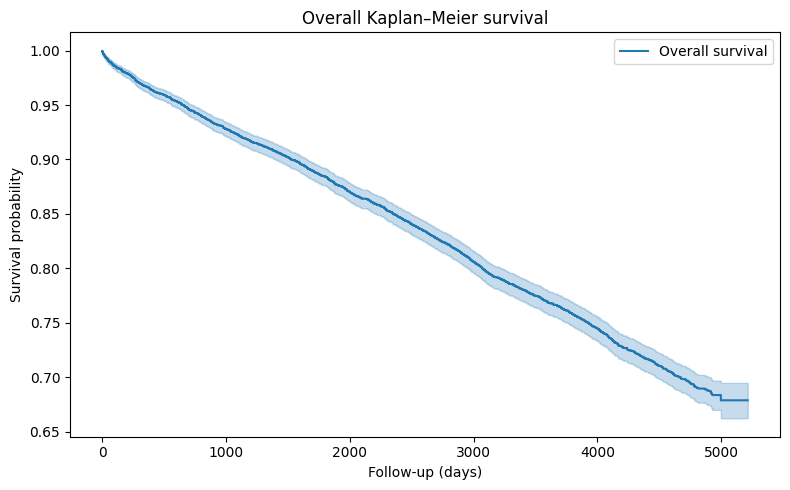

Median survival: inf


In [5]:
km=KaplanMeierFitter().fit(train.time,event_observed=train.event,label='Overall survival')
ax=km.plot_survival_function(ci_show=True,figsize=(8,5))
ax.set(xlabel='Follow-up (days)',ylabel='Survival probability',title='Overall Kaplan–Meier survival')
plt.tight_layout();plt.savefig(ANALYSIS_OUT/'overall_km.png',dpi=150);plt.show()
print('Median survival:',km.median_survival_time_)

## 06 — Survival by Sex

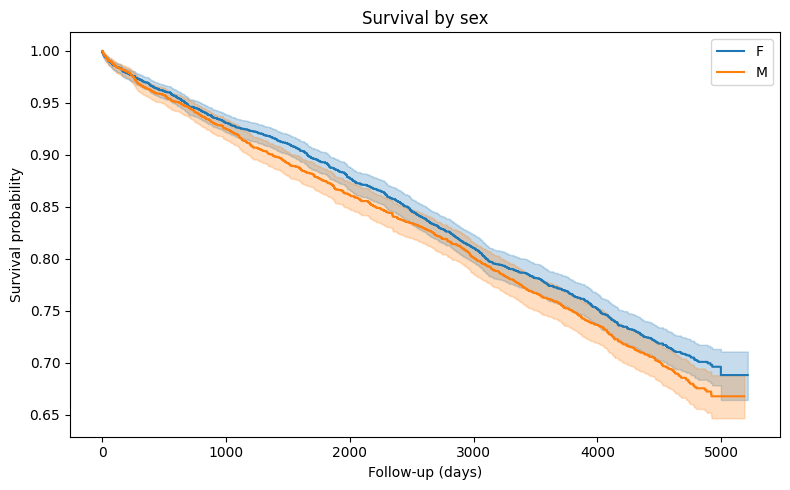

In [6]:
fig,ax=plt.subplots(figsize=(8,5))
for group,df in train.groupby('sex',observed=True):
    KaplanMeierFitter().fit(df.time,df.event,label=str(group)).plot_survival_function(ax=ax)
ax.set(xlabel='Follow-up (days)',ylabel='Survival probability',title='Survival by sex')
plt.tight_layout();plt.savefig(ANALYSIS_OUT/'km_by_sex.png',dpi=150);plt.show()

## 07 — Survival by MGUS

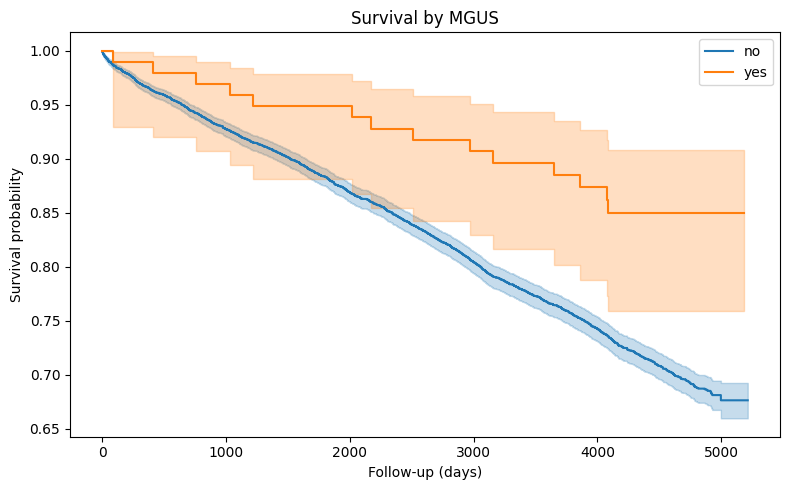

In [7]:
fig,ax=plt.subplots(figsize=(8,5))
for group,df in train.groupby('mgus',observed=True):
    KaplanMeierFitter().fit(df.time,df.event,label=str(group)).plot_survival_function(ax=ax)
ax.set(xlabel='Follow-up (days)',ylabel='Survival probability',title='Survival by MGUS')
plt.tight_layout();plt.savefig(ANALYSIS_OUT/'km_by_mgus.png',dpi=150);plt.show()

## 08 — Survival by Age Group

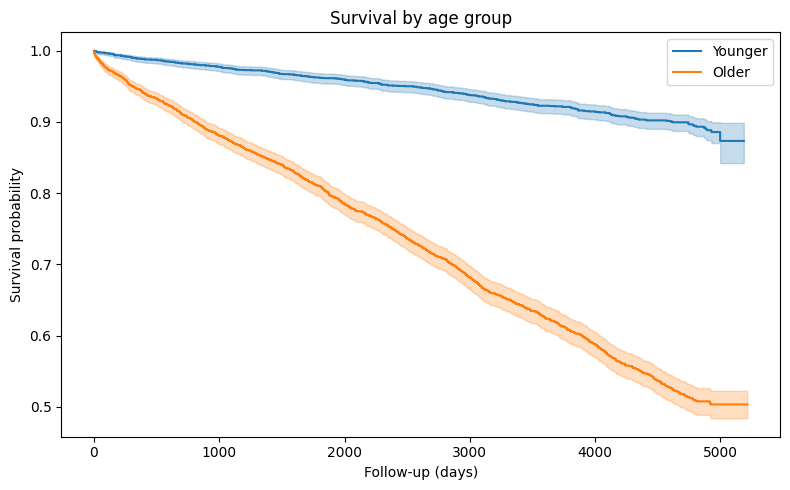

In [8]:
median_age=train.age.median()
age_group=np.where(train.age>=median_age,'Older','Younger')
fig,ax=plt.subplots(figsize=(8,5))
for group in ['Younger','Older']:
    mask=age_group==group
    KaplanMeierFitter().fit(train.loc[mask,'time'],train.loc[mask,'event'],label=group).plot_survival_function(ax=ax)
ax.set(xlabel='Follow-up (days)',ylabel='Survival probability',title='Survival by age group')
plt.tight_layout();plt.savefig(ANALYSIS_OUT/'km_by_age.png',dpi=150);plt.show()

## 09 — Log Rank Test by Sex

In [9]:
groups=train.sex.dropna().unique()
assert len(groups)==2
A=train[train.sex==groups[0]];B=train[train.sex==groups[1]]
sex_test=logrank_test(A.time,B.time,A.event,B.event)
print('Sex p-value:',sex_test.p_value)

Sex p-value: 0.06706061081751766


## 10 — Log Rank Test by MGUS

In [10]:
groups=train.mgus.dropna().unique()
assert len(groups)==2
A=train[train.mgus==groups[0]];B=train[train.mgus==groups[1]]
mgus_test=logrank_test(A.time,B.time,A.event,B.event)
print('MGUS p-value:',mgus_test.p_value)

MGUS p-value: 0.0035375737134008783


## 11 — Log Rank Test by Age Group

In [11]:
A=train[age_group=='Younger'];B=train[age_group=='Older']
age_test=logrank_test(A.time,B.time,A.event,B.event)
print('Age p-value:',age_test.p_value)

Age p-value: 7.380943465845424e-212


## 12 — Prepare Cox Features

In [12]:
cox_data=train[features+['time','event']].copy()
# Cox only: fit missing-value statistics on the training set; the held-out test is untouched.
num=metadata['numeric_features'];cat=metadata['categorical_features']
for col in num:
    cox_data[col]=pd.to_numeric(cox_data[col],errors='coerce')
    cox_data[col]=cox_data[col].fillna(cox_data[col].median())
for col in cat:
    mode=cox_data[col].mode(dropna=True)
    cox_data[col]=cox_data[col].astype('object').fillna(mode.iloc[0] if len(mode) else 'Missing').astype(str)
cox_data=pd.get_dummies(cox_data,columns=cat,drop_first=True,dtype=float)
feature_cols=[c for c in cox_data if c not in ['time','event']]
scaler=StandardScaler()
cox_data[feature_cols]=scaler.fit_transform(cox_data[feature_cols].astype(float))
assert np.isfinite(cox_data[feature_cols].to_numpy()).all()
print('Cox design:',cox_data.shape)

Cox design: (6299, 25)


/tmp/ipykernel_518/791895709.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cox_data[col]=cox_data[col].astype('object').fillna(mode.iloc[0] if len(mode) else 'Missing').astype(str)
/tmp/ipykernel_518/791895709.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cox_data[col]=cox_data[col].astype('object').fillna(mode.iloc[0] if len(mode) else 'Missing').astype(str)


## 13 — Fit Cox Proportional Hazards

In [13]:
cox=CoxPHFitter(penalizer=0.2)
cox.fit(cox_data,duration_col='time',event_col='event')
print('Training C-index:',cox.concordance_index_)

Training C-index: 0.7956218267511764


## 14 — Cox Coefficient Summary

In [14]:
summary=cox.summary[['coef','exp(coef)','p','exp(coef) lower 95%','exp(coef) upper 95%']].sort_values('p')
display(summary)
summary.to_csv(ANALYSIS_OUT/'cox_coefficients.csv')

,coef,exp(coef),p,exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,,,
age,0.588782,1.801792,9.649509e-209,1.735602,1.870508
flc.grp_10,0.148524,1.160121,9.302386e-16,1.118847,1.202918
lambda,0.081228,1.084618,2.816639e-05,1.044159,1.126645
kappa,0.076316,1.079303,4.279635e-05,1.040562,1.119487
sex_M,0.048853,1.050066,8.522254e-03,1.012533,1.088991
flc.grp_9,0.043716,1.044686,1.544195e-02,1.008372,1.082308
flc.grp_2,-0.041693,0.959164,4.279637e-02,0.921241,0.998648
flc.grp_8,0.035851,1.036501,5.143590e-02,0.999777,1.074575
flc.grp_3,-0.036376,0.964278,7.434103e-02,0.926512,1.003583


## 15 — Cox Hazard Ratios

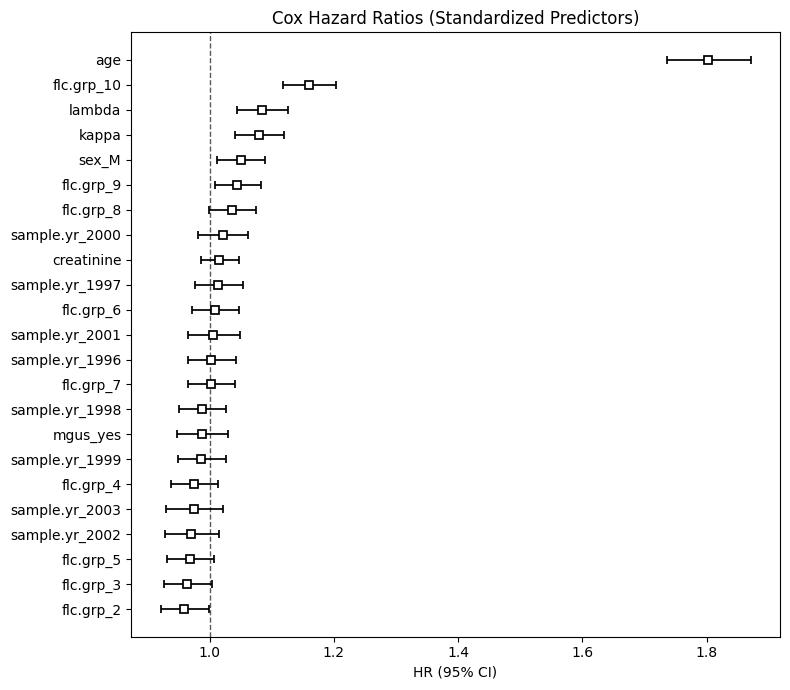

In [17]:
fig, ax = plt.subplots(figsize=(8, 7))

cox.plot(hazard_ratios=True, ax=ax)

ax.set_title("Cox Hazard Ratios (Standardized Predictors)")

plt.tight_layout()
plt.savefig(ANALYSIS_OUT / "cox_hazard_ratios.png", dpi=150)
plt.show()

## 16 — Proportional Hazards Check

In [19]:

from lifelines.statistics import proportional_hazard_test

# Use the same data used to fit the Cox model
ph = proportional_hazard_test(
    cox,
    cox_data,
    time_transform="rank"
)

ph_table = ph.summary.sort_values("p")

display(ph_table)

ph_table.to_csv(ANALYSIS_OUT / "ph_check.csv")

print(
    "Features with p < 0.05:",
    int((ph_table["p"] < 0.05).sum())
)


,test_statistic,p,-log2(p)
flc.grp_10,3.742531,0.053044,4.236665
flc.grp_6,2.039004,0.153310,2.705476
lambda,1.773450,0.182956,2.450434
flc.grp_8,0.957801,0.327742,1.609369
age,0.931358,0.334510,1.579878
sample.yr_2002,0.455055,0.499944,1.000161
flc.grp_2,0.436320,0.508904,0.974535
sample.yr_1999,0.380635,0.537264,0.896298
flc.grp_3,0.285364,0.593207,0.753393
flc.grp_9,0.249436,0.617472,0.695553


Features with p < 0.05: 0


## 17 — Training C-index

In [20]:
risk=cox.predict_partial_hazard(cox_data).to_numpy().ravel()
train_cindex=concordance_index(cox_data.time,-risk,cox_data.event)
print('Training C-index:',round(float(train_cindex),4))

Training C-index: 0.7956


## 18 — Save Survival Results

In [21]:
logrank={'sex':float(sex_test.p_value),'mgus':float(mgus_test.p_value),'age_group':float(age_test.p_value)}
(ANALYSIS_OUT/'logrank_tests.json').write_text(json.dumps(logrank,indent=2))
with open(ANALYSIS_OUT/'cox_lifelines_model.pkl','wb') as f: pickle.dump(cox,f)
summary_dict={'train_n':len(train),'events':int(train.event.sum()),'cox_train_cindex':float(train_cindex),'logrank_pvalues':logrank}
(ANALYSIS_OUT/'survival_results.json').write_text(json.dumps(summary_dict,indent=2))
print('Saved:',ANALYSIS_OUT)

Saved: /content/outputs_flchain/notebook_02
